In [0]:
%pip install seaborn
from pyspark.sql import functions as F
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

file_path = "/Volumes/workspace/default/health_data_volume/cleaned_base_cdi"

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
df = spark.read.parquet(file_path)

# pdf = pd.read_excel(pop_path, sheet_name=0)
# pdf.columns = [str(col).strip() for col in pdf.columns]
# pop_df = spark.createDataFrame(pdf)
# pop_df = pop_df.dropna()
# pop_df = pop_df.withColumn(
#     "Geographic Area",
#     F.trim(F.regexp_replace(F.col("Geographic Area"), r"^\.", "")),
# )

In [0]:
df.columns

['YearStart',
 'YearEnd',
 'LocationDesc',
 'Question',
 'DataValueType',
 'DataValueUnit',
 'Alcohol_Age_Age_0_44',
 'Alcohol_Age_Age_18_44',
 'Alcohol_Age_Age_45_64',
 'Alcohol_Age_Age___65',
 'Alcohol_Grade_Grade_10',
 'Alcohol_Grade_Grade_11',
 'Alcohol_Grade_Grade_12',
 'Alcohol_Grade_Grade_9',
 'Alcohol_Overall_Overall',
 'Alcohol_Race_Ethnicity_American_Indian_or_Alaska_Native__non_Hispanic',
 'Alcohol_Race_Ethnicity_Asian__non_Hispanic',
 'Alcohol_Race_Ethnicity_Black__non_Hispanic',
 'Alcohol_Race_Ethnicity_Hispanic',
 'Alcohol_Race_Ethnicity_Multiracial__non_Hispanic',
 'Alcohol_Race_Ethnicity_Native_Hawaiian_or_Other_Pacific_Islander__non_Hispanic',
 'Alcohol_Race_Ethnicity_White__non_Hispanic',
 'Alcohol_Sex_Female',
 'Alcohol_Sex_Male',
 'Arthritis_Age_Age_18_44',
 'Arthritis_Age_Age_45_64',
 'Arthritis_Age_Age___65',
 'Arthritis_Overall_Overall',
 'Arthritis_Race_Ethnicity_American_Indian_or_Alaska_Native__non_Hispanic',
 'Arthritis_Race_Ethnicity_Asian__non_Hispanic',
 '

In [0]:
# Select subset for inspection
subset = df.select("YearStart", "YearEnd", "Question", "LocationDesc", "DataValueType", "DataValueUnit", "Oral_Health_Overall_Overall", "Tobacco_Overall_Overall", "Asthma_Overall_Overall")
subset.show()

+---------+-------+--------------------+--------------+--------------------+-------------------+---------------------------+-----------------------+----------------------+
|YearStart|YearEnd|            Question|  LocationDesc|       DataValueType|      DataValueUnit|Oral_Health_Overall_Overall|Tobacco_Overall_Overall|Asthma_Overall_Overall|
+---------+-------+--------------------+--------------+--------------------+-------------------+---------------------------+-----------------------+----------------------+
|     2020|   2020|Binge drinking pr...|       Arizona|    Crude Prevalence|                  %|                       NULL|                   NULL|                  NULL|
|     2019|   2019|Binge drinking pr...|    New Mexico|    Crude Prevalence|                  %|                       NULL|                   NULL|                  NULL|
|     2020|   2020|Physical inactivi...|          Iowa|    Crude Prevalence|                  %|                       NULL|                

In [0]:
temp = subset.filter(F.col("Asthma_Overall_Overall").isNotNull())
temp.groupby("Question").count().orderBy(F.desc("count")).show()
temp.groupby("LocationDesc").count().orderBy(F.asc("count")).show()
print(temp.select("LocationDesc").distinct().count()) # All states are represented so we can use `Current asthma among adults` as one feature

+--------------------+-----+
|            Question|count|
+--------------------+-----+
|Asthma mortality ...|  231|
|Current asthma am...|  198|
+--------------------+-----+

+--------------+-----+
|  LocationDesc|count|
+--------------+-----+
|  South Dakota|    4|
|        Alaska|    4|
| New Hampshire|    4|
|       Vermont|    4|
|       Montana|    4|
|         Maine|    4|
|      Delaware|    4|
|       Wyoming|    4|
|  North Dakota|    4|
|  Rhode Island|    4|
| West Virginia|    4|
|         Idaho|    7|
|    New Jersey|    8|
|      Michigan|   10|
|      Maryland|   10|
|North Carolina|   10|
|     Wisconsin|   10|
|      Nebraska|   10|
|        Hawaii|   10|
|    Washington|   10|
+--------------+-----+
only showing top 20 rows
50


In [0]:
temp_2 = subset.filter(F.col("Tobacco_Overall_Overall").isNotNull()) # Current cigarette smoking among adults
# temp_2.groupby("Question").count().orderBy(F.desc("count")).show()
temp_2.filter(F.col("Question") == "Current cigarette smoking among adults").groupby("LocationDesc").count().orderBy(F.asc("count")).show()
print(temp_2.filter(F.col("Question") == "Current cigarette smoking among adults").select("LocationDesc").distinct().count()) # All 50 states represented so we can use 'Current cigarette smoking among adults'

+--------------+-----+
|  LocationDesc|count|
+--------------+-----+
|    New Jersey|    2|
|          Utah|    4|
|        Nevada|    4|
|     Louisiana|    4|
|    California|    4|
|      Oklahoma|    4|
|      Arkansas|    4|
|       Alabama|    4|
|      Virginia|    4|
|     Wisconsin|    4|
|North Carolina|    4|
|South Carolina|    4|
|       Arizona|    4|
|      Illinois|    4|
|       Indiana|    4|
| West Virginia|    4|
|       Florida|    4|
|       Montana|    4|
|      Michigan|    4|
|  North Dakota|    4|
+--------------+-----+
only showing top 20 rows
50


In [0]:
temp_3 = subset.filter(F.col("Oral_Health_Overall_Overall").isNotNull()) # Visited dentist or dental clinic in the past year among adults
# temp_3.groupby("Question").count().orderBy(F.desc("count")).show()
temp_3.filter(F.col("Question") == "Visited dentist or dental clinic in the past year among adults").groupby("LocationDesc").count().orderBy(F.asc("count")).show()
print(temp_3.filter(F.col("Question") == "Visited dentist or dental clinic in the past year among adults").select("LocationDesc").distinct().count()) # All states represented in `Visited dentist or dental clinic in the past year among adults` so we can use it as a feature

+--------------+-----+
|  LocationDesc|count|
+--------------+-----+
|          Iowa|    2|
| Massachusetts|    2|
|      Missouri|    2|
|         Texas|    2|
|      Illinois|    2|
|          Utah|    2|
|      Arkansas|    2|
|      Virginia|    2|
|       Wyoming|    2|
|   Mississippi|    2|
|        Hawaii|    2|
|      Michigan|    2|
|       Arizona|    2|
|   Connecticut|    2|
|      Maryland|    2|
|South Carolina|    2|
|          Ohio|    2|
|       Alabama|    2|
|       Florida|    2|
|  South Dakota|    2|
+--------------+-----+
only showing top 20 rows
50


In [0]:
subset = subset.filter(
    (F.col("Question") == "Current cigarette smoking among adults") |
    (F.col("Question") == "Visited dentist or dental clinic in the past year among adults") |
    (F.col("Question") == "Current asthma among adults")
)

subset = subset.filter(F.col("DataValueType") == "Crude Prevalence")

In [0]:
subset.show()

+---------+-------+--------------------+--------------+----------------+-------------+---------------------------+-----------------------+----------------------+
|YearStart|YearEnd|            Question|  LocationDesc|   DataValueType|DataValueUnit|Oral_Health_Overall_Overall|Tobacco_Overall_Overall|Asthma_Overall_Overall|
+---------+-------+--------------------+--------------+----------------+-------------+---------------------------+-----------------------+----------------------+
|     2020|   2020|Current asthma am...|  South Dakota|Crude Prevalence|            %|                       NULL|                   NULL|                   8.8|
|     2019|   2019|Current cigarette...|North Carolina|Crude Prevalence|            %|                       NULL|                   18.5|                  NULL|
|     2020|   2020|Current cigarette...|      Michigan|Crude Prevalence|            %|                       NULL|                   18.4|                  NULL|
|     2020|   2020|Current a

In [0]:
asthma_df = subset.filter(F.col("Question") == "Current asthma among adults")
asthma_df = (
    asthma_df.groupBy("LocationDesc")
    .agg(F.avg(F.col("Asthma_Overall_Overall").cast("double")).alias("asthma_rate"))
    .select("LocationDesc", "asthma_rate")
)

oral_df = subset.filter(F.col("Question") == "Visited dentist or dental clinic in the past year among adults")
oral_df = (
    oral_df.groupBy("LocationDesc")
    .agg(F.avg(F.col("Oral_Health_Overall_Overall").cast("double")).alias("dentist_visits"))
    .select("LocationDesc", "dentist_visits")
)

cig_df = subset.filter(F.col("Question") == "Current cigarette smoking among adults")
cig_df = (
    cig_df.groupBy("LocationDesc")
    .agg(F.avg(F.col("Tobacco_Overall_Overall").cast("double")).alias("smokers"))
    .select("LocationDesc", "smokers")
)

In [0]:
asthma_df.show()
print(asthma_df.filter(F.col("asthma_rate").isNotNull()).count())

+--------------+------------------+
|  LocationDesc|       asthma_rate|
+--------------+------------------+
|      Maryland|               9.6|
|      Michigan|             11.95|
|      Nebraska| 8.399999999999999|
|   Mississippi|              10.0|
|South Carolina|             10.15|
|     Wisconsin|10.850000000000001|
| West Virginia|             12.75|
|       Vermont|              11.9|
|        Alaska|              10.3|
|         Maine|              12.1|
|  South Dakota|               9.0|
|     Minnesota|               8.9|
|   Connecticut|             11.25|
|          Iowa|              9.25|
|        Nevada|              9.95|
|       Florida|               7.9|
|North Carolina|              8.45|
|       Arizona|              10.3|
|  Pennsylvania|              11.2|
|    Washington|             10.45|
+--------------+------------------+
only showing top 20 rows
50


In [0]:
oral_df.show()
print(oral_df.filter(F.col("dentist_visits").isNotNull()).count())

+--------------+--------------+
|  LocationDesc|dentist_visits|
+--------------+--------------+
|      Maryland|          66.2|
|       Florida|          61.2|
|          Ohio|          65.3|
|      Michigan|          69.2|
|South Carolina|          67.7|
|  South Dakota|          69.5|
|      Arkansas|          57.0|
|   Connecticut|          73.2|
| Massachusetts|          73.3|
|      Virginia|          70.0|
|      Missouri|          63.0|
|       Wyoming|          65.4|
|          Iowa|          68.1|
|       Arizona|          61.2|
|North Carolina|          65.5|
|       Vermont|          68.5|
| West Virginia|          57.7|
|  Rhode Island|          74.2|
|         Maine|          66.7|
|  Pennsylvania|          68.1|
+--------------+--------------+
only showing top 20 rows
50


In [0]:
cig_df.show()
print(cig_df.filter(F.col("smokers").isNotNull()).count())

+--------------+------------------+
|  LocationDesc|           smokers|
+--------------+------------------+
|        Nevada|             14.95|
|North Carolina|              17.5|
|      Michigan|18.549999999999997|
|       Florida|             14.75|
| West Virginia|23.200000000000003|
|South Carolina|              17.8|
|      Illinois|              13.6|
|      Oklahoma|              19.0|
|       Montana|              16.5|
|      Virginia|              13.8|
|  North Dakota|              17.2|
|      Missouri|18.700000000000003|
|      Maryland|              11.8|
|          Ohio|             20.05|
|     Wisconsin|             15.45|
|    Washington|             12.05|
|         Maine|             17.05|
|      Kentucky|              22.5|
|       Georgia|             16.05|
|    California|              9.45|
+--------------+------------------+
only showing top 20 rows
50


In [0]:
# Combine all three dataframes
temp_df = cig_df.join(asthma_df, on = "LocationDesc", how = "outer")
full_df = oral_df.join(temp_df, on = "LocationDesc", how = "outer")

In [0]:
null_counts = full_df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c) 
    for c in full_df.columns
])

null_counts.show()

+------------+--------------+-------+-----------+
|LocationDesc|dentist_visits|smokers|asthma_rate|
+------------+--------------+-------+-----------+
|           0|             0|      0|          0|
+------------+--------------+-------+-----------+



In [0]:
full_df.show()

+--------------+--------------+------------------+------------------+
|  LocationDesc|dentist_visits|           smokers|       asthma_rate|
+--------------+--------------+------------------+------------------+
|        Nevada|          60.8|             14.95|              9.95|
|      Maryland|          66.2|              11.8|               9.6|
|        Hawaii|          74.7|             11.95|               9.8|
|North Carolina|          65.5|              17.5|              8.45|
|      Michigan|          69.2|18.549999999999997|             11.95|
|       Florida|          61.2|             14.75|               7.9|
|          Ohio|          65.3|             20.05|             11.25|
|       Arizona|          61.2|              14.0|              10.3|
|  Rhode Island|          74.2|              13.4|             12.35|
| West Virginia|          57.7|23.200000000000003|             12.75|
|South Carolina|          67.7|              17.8|             10.15|
|     Wisconsin|    

In [0]:
full_df.select("dentist_visits", "smokers", "asthma_rate").summary().show() # Summary statistics

+-------+-----------------+------------------+------------------+
|summary|   dentist_visits|           smokers|       asthma_rate|
+-------+-----------------+------------------+------------------+
|  count|               50|                50|                50|
|   mean|           65.666|15.814000000000004|10.297999999999996|
| stddev|4.746496452271777|3.2913002207117397|1.1751230938562505|
|    min|             57.0|              8.05|               7.9|
|    25%|             61.4|              13.8|               9.4|
|    50%|             66.3|              15.5|              10.3|
|    75%|             68.5|             18.45|             11.25|
|    max|             74.7|23.200000000000003|             12.75|
+-------+-----------------+------------------+------------------+



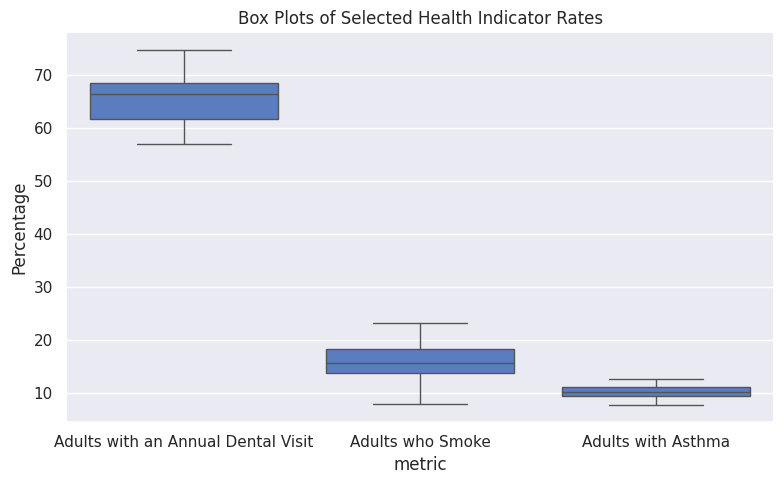

In [0]:
# Side by side box plots + outlier detection -- No outliers
pdf = full_df.toPandas()
sns.set_theme(style="darkgrid", palette="muted")

long_df = pdf[['dentist_visits', 'smokers', 'asthma_rate']].melt(
    value_vars=['dentist_visits', 'smokers', 'asthma_rate'],
    var_name="metric",
    value_name="rate",
).dropna(subset=["rate"])

plt.figure(figsize=(8, 5))
ax = sns.boxplot(data=long_df, x="metric", y="rate")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["Adults with an Annual Dental Visit", "Adults who Smoke", "Adults with Asthma"])
plt.title("Box Plots of Selected Health Indicator Rates")
plt.ylabel("Percentage")
plt.tight_layout()
plt.show()

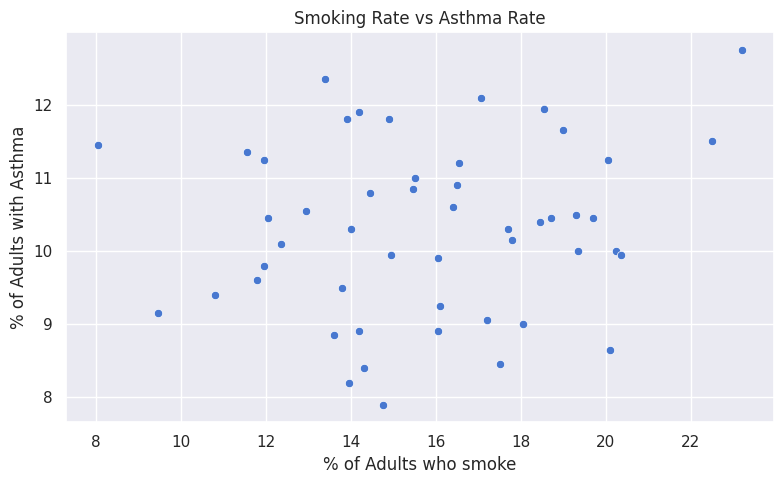

In [0]:
# Scatter plots
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=pdf, x="smokers", y="asthma_rate")
plt.title("Smoking Rate vs Asthma Rate")
plt.xlabel("% of Adults who Smoke")
plt.ylabel("% of Adults with Asthma")

plt.tight_layout()
plt.show()

0.40677185233080276


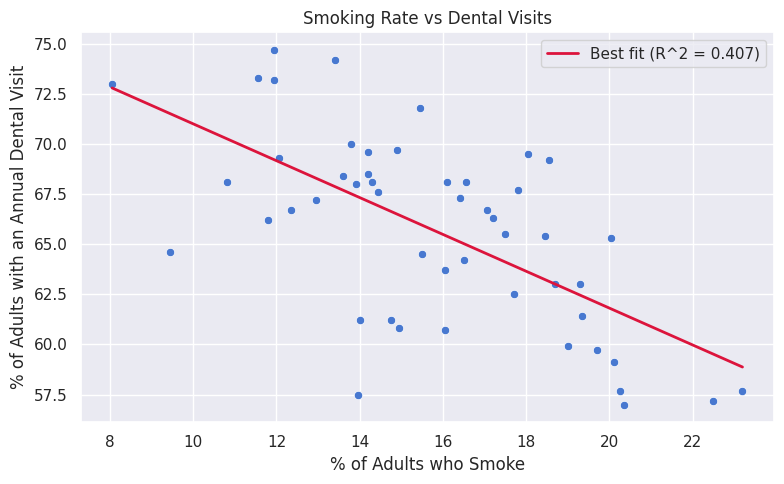

In [0]:
res = stats.linregress(pdf['smokers'], pdf['dentist_visits'])
slope = res.slope
intercept = res.intercept
r_squared = res.rvalue**2

x_line = np.linspace(pdf['smokers'].min(), pdf['smokers'].max(), 200)
y_line = slope * x_line + intercept

print(r_squared)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=pdf, x="smokers", y="dentist_visits")
plt.title("Smoking Rate vs Dental Visits")
plt.xlabel("% of Adults who Smoke")
plt.ylabel("% of Adults with an Annual Dental Visit")

plt.plot(
    x_line,
    y_line,
    color="crimson",
    linewidth=2,
    label=f"Best fit (R^2 = {r_squared:.3f})",
)

plt.legend()
plt.tight_layout()
plt.show()